# Cats vs Dogs, small CNN

Classic binary classification on the real Kaggle / Microsoft Asirra Cats vs Dogs photos (`microsoft/cats_vs_dogs` on Hugging Face, about 23.4K images). The full set is around 800MB, so I read 12 evenly spaced parquet row groups from the cat file and 12 from the dog file: 2,210 photos (some row groups hold fewer than 100), resized to 64x64. The CNN is trained from scratch on CPU for 12 epochs, which takes about a minute.

A small from-scratch CNN on about 2,200 low-res photos is a weak setup on purpose. It shows what the plain pipeline gets before any transfer learning.

In [1]:
import io
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

torch.set_num_threads(2)
np.random.seed(5); torch.manual_seed(5)

In [2]:
SIZE = 64
GROUPS_PER_CLASS = 12
fs = HfFileSystem()
ROOT = "datasets/microsoft/cats_vs_dogs@refs%2Fconvert%2Fparquet/default/train/"

imgs, labels = [], []
for fname in ["0000.parquet", "0001.parquet"]:          # first file is cats, second is dogs
    pf = pq.ParquetFile(fs.open(ROOT + fname))
    groups = np.linspace(0, pf.metadata.num_row_groups - 1, GROUPS_PER_CLASS).astype(int)
    for g in groups:
        for row in pf.read_row_group(int(g)).to_pylist():
            im = Image.open(io.BytesIO(row["image"]["bytes"])).convert("RGB").resize((SIZE, SIZE))
            imgs.append(np.asarray(im, dtype=np.float32) / 255.0)
            labels.append(row["labels"])           # 0 = cat, 1 = dog
X = np.stack(imgs); y = np.array(labels, dtype=np.int64)
print('real photos:', X.shape, '| dog rate:', y.mean().round(3))

real photos: (2210, 64, 64, 3) | dog rate: 0.484


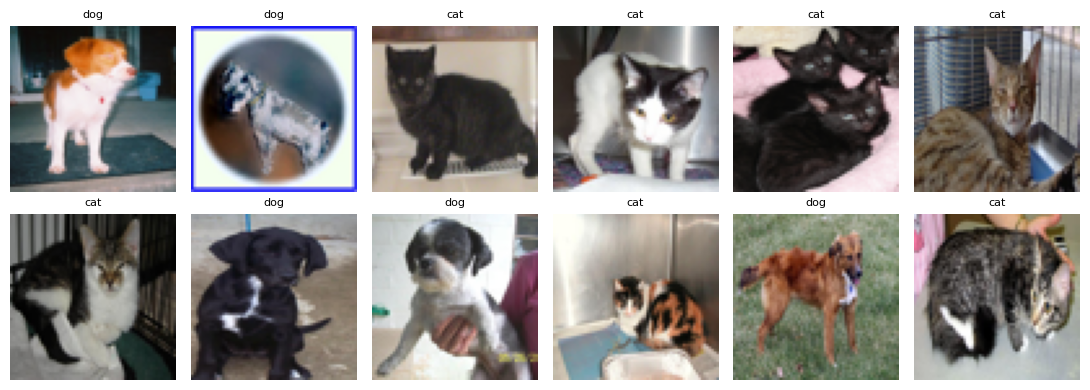

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, idx in zip(axes.flat, np.random.choice(len(X), 12, replace=False)):
    ax.imshow(X[idx]); ax.set_title('cat' if y[idx] == 0 else 'dog', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()

In [4]:
Xt = torch.tensor(X).permute(0, 3, 1, 2)
yt = torch.tensor(y)
Xtr, Xte, ytr, yte = train_test_split(Xt.numpy(), yt.numpy(), test_size=0.2, stratify=yt.numpy(), random_state=5)
Xtr = torch.tensor(Xtr); Xte = torch.tensor(Xte); ytr = torch.tensor(ytr); yte = torch.tensor(yte)

class CatDogCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(3, 8, 3, padding=1)
        self.c2 = nn.Conv2d(8, 16, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(16 * 16 * 16, 32)  # 64x64 input, two 2x pools -> 16x16
        self.fc2 = nn.Linear(32, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.c1(x)))
        x = self.pool(F.relu(self.c2(x)))
        x = x.flatten(1)
        return self.fc2(F.relu(self.fc1(x)))

model = CatDogCNN()
# tried SGD first, Adam converged in fewer epochs at this scale
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

batch = 32
for ep in range(12):  # 12 epochs, about a minute on CPU at this size
    model.train(); perm = torch.randperm(len(Xtr)); losses = []
    for i in range(0, len(perm), batch):
        idx = perm[i:i + batch]
        opt.zero_grad()
        out = model(Xtr[idx])
        loss = F.cross_entropy(out, ytr[idx])
        loss.backward(); opt.step()
        losses.append(loss.item())
    print(f'epoch {ep}  mean_loss={np.mean(losses):.4f}')

epoch 0  mean_loss=0.6980


epoch 1  mean_loss=0.6903


epoch 2  mean_loss=0.6859


epoch 3  mean_loss=0.6607


epoch 4  mean_loss=0.6176


epoch 5  mean_loss=0.6029


... (2 outputs left out)

epoch 8  mean_loss=0.5455


epoch 9  mean_loss=0.5267


epoch 10  mean_loss=0.4880


epoch 11  mean_loss=0.4695


In [5]:
model.eval()
with torch.no_grad():
    logits = model(Xte)
    preds = logits.argmax(1).numpy()
    probs = F.softmax(logits, dim=1)[:, 1].numpy()

print(f'test acc : {accuracy_score(yte.numpy(), preds):.3f}')
print(f'test auc : {roc_auc_score(yte.numpy(), probs):.3f}')
print('confusion:'); print(confusion_matrix(yte.numpy(), preds))

test acc : 0.661
test auc : 0.758
confusion:
[[177  51]
 [ 99 115]]


## Notes / takeaways

On 442 held-out photos the two-conv-layer CNN gets 66.1% accuracy and ROC-AUC 0.758. That's well above chance but far from what this task allows; the old Kaggle competition was won with around 99% accuracy. With 3 epochs it barely moved off 50% (it predicted "cat" for almost everything), so the 12 epochs here matter. The training loss was still dropping at the end (0.47), and it still misses almost half of the dogs (99 of 214).

What I'd change for a real result: (1) go to at least 128x128 inputs, since at 64x64 a lot of the fur and face detail is gone, (2) add `RandomHorizontalFlip` + small color jitter, (3) use the full 23K images, and most of all (4) switch to transfer learning. A frozen ImageNet backbone with a linear head (the notebook 59 pattern) should get into the 90s quickly, because cats and dogs are both well covered by ImageNet.

MobileNetV2 via torch.hub does work on CPU but the per-batch latency at 224x224 is rough, so for a CPU-only environment I'd cap the input at 128x128.